# Forecasted exogenous variables

Many useful exogenous variables are not known in advance: they are forecasts themselves. Weather forecasts, market price estimates, sales plans or production schedules are only available as estimates when the prediction is made, and they are **revised over time**: the value for next Friday published on Wednesday differs from the one published on Thursday, and both differ from the value finally observed.

**The problem**

The history of a forecasted variable has two timestamps: the time the value refers to and the time it was published. Datasets usually keep a single value per timestamp, most often the observed one. If a backtest uses it to make predictions, each fold uses values that were not available when that prediction would have been made (**look-ahead bias**). The metrics then overestimate the performance the model will have in production, and the bias grows with the error of the forecasts of the variable, which usually increases with the horizon.

**The solution**

Each prediction of the backtest must use only the values that were available when it was made. In skforecast this takes two steps, with no special arguments:

1. **Build a point-in-time (or *as-of*) exogenous variable**: for each timestamp, keep the last value published up to the moment the prediction is made in production. The result is an ordinary exogenous column, built with a few lines of pandas.
2. **Reproduce the production process in the backtest**: [`TimeSeriesFold`](https://skforecast.org/latest/api/model_selection#skforecast.model_selection._split.TimeSeriesFold) defines when each prediction is made and what it covers, with `steps` (horizon), `gap` (time between the last observed value and the first predicted one), `fold_stride` (how often predictions are made) and `refit`.

Since the result is a regular `exog`, it works with every forecaster, every backtesting and hyperparameter search function, and with `predict()` in production. The only condition is that each timestamp is evaluated from a single moment, that is, that the folds do not overlap (`fold_stride >= steps`), because the column holds one value per timestamp.

This guide uses temperature forecasts as an example, with the `vic_electricity` dataset, but the same approach applies to any forecasted exogenous variable. It reproduces a weekly forecasting process in the backtest with the temperature forecasts available at each prediction, measures how much the metrics change when the observed temperature is used instead, compares training the model with the observed values and with the forecasts, and makes the predictions in production.

## Libraries and data

In [1]:
# Libraries
# ==============================================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from lightgbm import LGBMRegressor
from skforecast.datasets import fetch_dataset
from skforecast.recursive import ForecasterRecursive
from skforecast.model_selection import TimeSeriesFold, backtesting_forecaster
from skforecast.plot import set_dark_theme

The `vic_electricity` dataset contains the half-hourly electricity demand of Victoria (Australia), the temperature in Melbourne and a holiday indicator, from 2012 to 2014. Its index is in UTC. The data are converted to Australian Eastern Standard Time (UTC+10) without daylight saving time, so that every day has 24 hours and the weekly prediction is always made at the same time of day, and they are aggregated to hourly values.

Calendar features (hour, day of the week and month) are added as exogenous variables. Like the holiday indicator, they are known in advance, so they do not have the problem described in this guide.

In [2]:
# Download data
# ==============================================================================
data = fetch_dataset(name="vic_electricity")

╭──────────────────────────────────────────────── vic_electricity ────────────────────────────────────────────────╮
│ Description:                                                                                                    │
│ Half-hourly electricity demand for Victoria, Australia. `Time` is in UTC (suffix Z, parsed as a naive           │
│ datetime); `Date` and `Holiday` refer to local time in Melbourne (UTC+10, UTC+11 in summer).                    │
│                                                                                                                 │
│ Source:                                                                                                         │
│ O'Hara-Wild M, Hyndman R, Wang E, Godahewa R (2022). tsibbledata: Diverse Datasets for 'tsibble'.               │
│ https://tsibbledata.tidyverts.org/, https://github.com/tidyverts/tsibbledata/.                                  │
│ https://tsibbledata.tidyverts.org/reference/vic_elec.html                                                       │
│                                                                                                                 │
│ URL:                                                                                                            │
│ https://raw.githubusercontent.com/skforecast/skforecast-datasets/main/data/vic_electricity.csv                  │
│                                                                                                                 │
│ Shape: 52608 rows x 4 columns                                                                                   │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

In [3]:
# Data preparation
# ==============================================================================
# Australian Eastern Standard Time, UTC+10 (the sign of Etc time zones is inverted)
data.index = data.index.tz_localize("UTC").tz_convert("Etc/GMT-10").tz_localize(None)
data = (
    data.resample("h")
    .agg({"Demand": "mean", "Temperature": "mean", "Holiday": "max"})
    .loc["2012-01-01 00:00":"2014-12-30 23:00"]
)
data["Holiday"] = data["Holiday"].astype(int)
data["hour"] = data.index.hour
data["day_of_week"] = data.index.dayofweek
data["month"] = data.index.month
calendar_features = ["Holiday", "hour", "day_of_week", "month"]
data.head()

,Demand,Temperature,Holiday,hour,day_of_week,month
Time,,,,,,
2012-01-01 00:00:00,3963.264688,20.625,1,0,6,1
2012-01-01 01:00:00,3950.913495,20.325,1,1,6,1
2012-01-01 02:00:00,3627.860675,19.850,1,2,6,1
2012-01-01 03:00:00,3396.251676,19.025,1,3,6,1
2012-01-01 04:00:00,3317.992230,18.725,1,4,6,1


## Forecasting process and backtesting

The backtest must reproduce the way predictions are made in production. In this example, every Tuesday at 10:00 the hourly demand of the next 7 days, from Wednesday 00:00 to Tuesday 23:00, is predicted. At that time, the last observed value of demand is the one of 09:00 (the mean from 09:00 to 10:00), and the most recent temperature forecast is the last one published at or before 10:00.

```text
Tuesday 05:00                     last temperature forecast published
Tuesday 10:00                     predictions are made (last observed demand: 09:00)
Tuesday 10:00 to 23:00            gap: predicted and discarded
Wednesday 00:00 to Tuesday 23:00  week predicted and evaluated
```

This process is defined with [`TimeSeriesFold`](https://skforecast.org/latest/api/model_selection#skforecast.model_selection._split.TimeSeriesFold):

- `steps=168`: 7 days of hourly predictions.
- `gap=14`: the hours from 10:00 to 23:00 of Tuesday are predicted but not evaluated.
- `fold_stride=168`: new predictions every week.
- `initial_train_size`: the observations up to Tuesday 31 December 2013 at 09:00, so that the first prediction is made that day at 10:00 and the backtest covers 2014.
- `refit=False`: the model is trained once, with the data before the first prediction.

The forecaster uses as predictors the demand of the last 3 hours and of the same hours one day and one week before, together with the exogenous variables.

In [4]:
# Backtesting configuration and forecaster
# ==============================================================================
initial_train_size = len(data.loc[:"2013-12-31 09:00"])
cv = TimeSeriesFold(
    steps              = 7 * 24,
    gap                = 14,
    fold_stride        = 7 * 24,
    initial_train_size = initial_train_size,
    refit              = False,
    verbose            = False,
)
forecaster = ForecasterRecursive(
    estimator = LGBMRegressor(random_state=123, verbose=-1),
    lags      = [1, 2, 3, 23, 24, 25, 167, 168, 169],
)

## Archive of forecasts

In production, the temperature of the coming days is only known through the forecasts that a weather service publishes periodically. The archive of these forecasts has one row per forecast value: the time it refers to (`timestamp`), the time it was published (`published_at`) and the value (`temperature`). Each timestamp appears many times, once for each forecast that covered it.

`vic_electricity` only contains the observed temperature, so the archive is simulated: a new forecast is published every 6 hours, 5 hours after the run of the weather model, and covers the next 8 days. Its error grows with the horizon and persists for a few hours, as in real forecasts: both were calibrated with archived temperature forecasts for Melbourne (2023 and 2024) from [Open-Meteo](https://open-meteo.com/) (CC BY 4.0). In a real project, this table is provided by the weather service or built by storing each forecast when it is received.

In [5]:
# Simulated archive of temperature forecasts
# ==============================================================================
rng = np.random.default_rng(seed=123)
runs = pd.date_range(data.index[0] - pd.Timedelta(8, unit="D"), data.index[-1], freq="6h")
horizon = np.arange(1, 8 * 24 + 1)  # Hours after the run of the weather model
error_std = np.interp(
    horizon,
    [24, 48, 72, 96, 120, 144, 168],
    [1.40, 1.53, 1.70, 2.01, 2.42, 2.71, 3.18],
)

# Errors correlated over the horizon of each run
noise = rng.normal(size=(len(runs), len(horizon)))
error = np.empty_like(noise)
error[:, 0] = noise[:, 0]
for h in range(1, len(horizon)):
    error[:, h] = 0.82 * error[:, h - 1] + np.sqrt(1 - 0.82**2) * noise[:, h]

archive = pd.DataFrame({
    "run": np.repeat(runs, len(horizon)),
    "horizon": np.tile(horizon, len(runs)),
    "error": (error * error_std).ravel(),
})
archive["timestamp"] = archive["run"] + pd.to_timedelta(archive["horizon"], unit="h")
archive["published_at"] = archive["run"] + pd.Timedelta(5, unit="h")
archive = archive[
    archive["timestamp"].isin(data.index)
    & (archive["timestamp"] > archive["published_at"])
]
archive["temperature"] = (
    data.loc[archive["timestamp"], "Temperature"].to_numpy() + archive["error"]
).round(1)
archive = archive[["timestamp", "published_at", "temperature"]].reset_index(drop=True)
archive.head()

,timestamp,published_at,temperature
0,2012-01-01 00:00:00,2011-12-24 05:00:00,23.7
1,2012-01-01 00:00:00,2011-12-24 11:00:00,15.7
2,2012-01-01 01:00:00,2011-12-24 11:00:00,13.6
3,2012-01-01 02:00:00,2011-12-24 11:00:00,12.2
4,2012-01-01 03:00:00,2011-12-24 11:00:00,14.5


Each hour has many forecasts, published at different times. For example, these are the last ones published for 15:00 on 15 January 2014, a day of the January 2014 heatwave in Melbourne:

In [6]:
# Forecasts published for one hour
# ==============================================================================
timestamp = pd.Timestamp("2014-01-15 15:00")
print(f"Observed temperature: {data.loc[timestamp, 'Temperature']:.1f} °C")
archive[archive["timestamp"] == timestamp].tail(8)

Observed temperature: 37.3 °C


,timestamp,published_at,temperature
559191,2014-01-15 15:00:00,2014-01-13 17:00:00,37.5
559372,2014-01-15 15:00:00,2014-01-13 23:00:00,39.3
559553,2014-01-15 15:00:00,2014-01-14 05:00:00,39.2
559734,2014-01-15 15:00:00,2014-01-14 11:00:00,38.5
559915,2014-01-15 15:00:00,2014-01-14 17:00:00,35.6
560096,2014-01-15 15:00:00,2014-01-14 23:00:00,39.1
560277,2014-01-15 15:00:00,2014-01-15 05:00:00,36.0
560458,2014-01-15 15:00:00,2014-01-15 11:00:00,37.4


## Backtesting with the temperature available at prediction time

For each hour, the point-in-time temperature is the last forecast published at or before the moment when that hour is predicted: 10:00 on the Tuesday before its week.

<p style="text-align: center">
    <img src="../img/diagram-backtesting-forecasted-exogenous-variables.png" alt="Three weekly folds and the exogenous column: observed temperature in the training period and, for each week, the forecasts published up to its prediction" style="width: 700px;">
    <br>
    <font size="2.5"> <i>Folds of the backtest and values of the exogenous column</i></font>
</p>

This moment is obtained from the parameters of `TimeSeriesFold` (`initial_train_size`, `gap` and `fold_stride`) and not from the calendar, so the exogenous variable and the folds always describe the same process. The same rule is applied to the hours before the first fold.

In [7]:
# Moment when each hour is predicted: start of the fold that evaluates it
# ==============================================================================
position = np.arange(len(data))
fold = (position - (cv.initial_train_size + cv.gap)) // cv.fold_stride
prediction_time = pd.Series(
    data.index[cv.initial_train_size] + fold * cv.fold_stride * data.index.freq,
    index=data.index,
)
prediction_time.loc["2014-01-07 22:00":"2014-01-08 01:00"]

Time
2014-01-07 22:00:00   2013-12-31 10:00:00
2014-01-07 23:00:00   2013-12-31 10:00:00
2014-01-08 00:00:00   2014-01-07 10:00:00
2014-01-08 01:00:00   2014-01-07 10:00:00
Freq: h, dtype: datetime64[ns]

The hours of Tuesday 7 January 2014 are predicted on Tuesday 31 December 2013 at 10:00, and those of Wednesday 8 January, the first day of the next week, on Tuesday 7 January at 10:00. The following function selects, for each timestamp, the last value published at or before its prediction time. If nothing was published for a timestamp before that moment, its value is missing (`NaN`). This is frequent in real archives and can go unnoticed, because estimators such as LightGBM accept missing values, so the number of hours without a forecast is checked.

In [8]:
# Point-in-time values of a forecasted variable
# ==============================================================================
def point_in_time(archive, prediction_time, value):
    """
    Last value of each timestamp published at or before its prediction time.
    """
    archive = archive.merge(
        prediction_time.rename("prediction_time"), left_on="timestamp", right_index=True
    )
    archive = archive[archive["published_at"] <= archive["prediction_time"]]
    values = archive.sort_values("published_at").groupby("timestamp")[value].last()

    return values.reindex(prediction_time.index)


temperature_forecast = point_in_time(archive, prediction_time, value="temperature")
temperature_mae = (temperature_forecast - data["Temperature"]).loc["2014"].abs().mean()
print(f"Hours without a forecast: {temperature_forecast.isna().sum()}")
print(f"MAE of the temperature forecasts in 2014: {temperature_mae:.2f} °C")

Hours without a forecast: 0
MAE of the temperature forecasts in 2014: 1.84 °C


The model is trained with the observed temperature and the predictions of the backtest use the forecasts, as happens in production: when the model is trained, the temperature of the past is already known, and when it predicts, only forecasts exist for the following days. In addition, the observed values are available for the whole history, whereas an archive of forecasts often covers only the most recent period. With `refit=False` the model is trained only once, with the data before the first prediction, so a single exogenous column can hold both: the observed temperature in the training period and the forecasts after it. The backtest is run with [`backtesting_forecaster`](https://skforecast.org/latest/api/model_selection#skforecast.model_selection._validation.backtesting_forecaster).

The hours of the `gap` (Tuesday from 10:00 to 23:00) are also predicted in each fold, although their predictions are discarded. They are evaluated in the previous fold and the column holds one value per hour, so they keep the forecasts of the previous week, whereas in production the most recent ones are used. This uses no future information and has a small effect on the metric. The opposite choice, the most recent forecasts, would leak information into the previous fold.

In [9]:
# Backtesting with the temperature available at prediction time
# ==============================================================================
is_train = np.arange(len(data)) < initial_train_size
exog_train_observed = data[calendar_features].assign(
    temperature=data["Temperature"].where(is_train, temperature_forecast)
)
metric_train_observed, _ = backtesting_forecaster(
    forecaster = forecaster,
    y          = data["Demand"],
    exog       = exog_train_observed,
    cv         = cv,
    metric     = "mean_absolute_error",
)
mae_train_observed = metric_train_observed.at[0, "mean_absolute_error"]
print(f"MAE with the temperature available at prediction time: {mae_train_observed:.1f}")

100%|██████████| 52/52 [00:00<00:00, 81.31it/s]

MAE with the temperature available at prediction time: 227.0


Each week is predicted with the temperature forecasts that were available on Tuesday at 10:00, so this error is a realistic estimate of the one the model will have in production.

## Comparison with the observed temperature

The usual approach is to use the observed temperature as an exogenous variable, both to train the model and to make the predictions of the backtest. It needs no archive of forecasts, but each week is predicted with the temperature observed during that week, which was not known on Tuesday at 10:00. To measure the effect, the same forecaster is evaluated with the observed temperature and, for reference, without temperature, using only the calendar features.

In [10]:
# Backtesting with the observed temperature
# ==============================================================================
exog_observed = data[calendar_features].assign(temperature=data["Temperature"])
metric_observed, _ = backtesting_forecaster(
    forecaster = forecaster,
    y          = data["Demand"],
    exog       = exog_observed,
    cv         = cv,
    metric     = "mean_absolute_error",
)
mae_observed = metric_observed.at[0, "mean_absolute_error"]
print(f"MAE with the observed temperature: {mae_observed:.1f}")
print(
    f"Increase with the temperature available at prediction time: "
    f"{mae_train_observed / mae_observed - 1:.1%}"
)

100%|██████████| 52/52 [00:00<00:00, 86.41it/s]

MAE with the observed temperature: 209.9
Increase with the temperature available at prediction time: 8.1%


In [11]:
# Backtesting without temperature
# ==============================================================================
metric_no_temperature, _ = backtesting_forecaster(
    forecaster = forecaster,
    y          = data["Demand"],
    exog       = data[calendar_features],
    cv         = cv,
    metric     = "mean_absolute_error",
)
mae_no_temperature = metric_no_temperature.at[0, "mean_absolute_error"]
print(f"MAE without temperature: {mae_no_temperature:.1f}")

100%|██████████| 52/52 [00:00<00:00, 74.09it/s]

MAE without temperature: 284.2


The backtest with the observed temperature is optimistic: its error is 209.9, and with the forecasts available at prediction time it is 227.0, 8.1% higher. It makes the model look better than it will be in production. Even so, the forecasted temperature is still very useful: the error is 20% lower than without temperature (284.2).

## Training with the forecasts

If the archive covers the whole history, the model can also be trained with the forecasts that were available at each moment, applying the same point-in-time rule to every hour. The model then learns how reliable the forecasts are, and the exogenous column is the same in training and prediction, so it also works with `refit=True`. The column of the first backtest, with observed values and forecasts, would not be valid with `refit=True`: the hours predicted with forecasts in one fold become training data in the following ones, where they should have the observed values.

In [12]:
# Backtesting with the model trained on the forecasts
# ==============================================================================
exog_train_forecasts = data[calendar_features].assign(temperature=temperature_forecast)
metric_train_forecasts, _ = backtesting_forecaster(
    forecaster = forecaster,
    y          = data["Demand"],
    exog       = exog_train_forecasts,
    cv         = cv,
    metric     = "mean_absolute_error",
)
mae_train_forecasts = metric_train_forecasts.at[0, "mean_absolute_error"]
print(f"MAE with the model trained on the forecasts: {mae_train_forecasts:.1f}")

100%|██████████| 52/52 [00:00<00:00, 81.20it/s]

MAE with the model trained on the forecasts: 238.9


In [13]:
# Summary of results
# ==============================================================================
results = pd.DataFrame({
    "temperature used to train": ["none", "observed", "observed", "forecasts"],
    "temperature used to predict": ["none", "observed", "forecasts", "forecasts"],
    "MAE": [mae_no_temperature, mae_observed, mae_train_observed, mae_train_forecasts],
})
results.round(1)

,temperature used to train,temperature used to predict,MAE
0,none,none,284.2
1,observed,observed,209.9
2,observed,forecasts,227.0
3,forecasts,forecasts,238.9


In this example, training with the observed temperature gives a lower error than training with the forecasts (227.0 versus 238.9), but the difference depends on the simulated errors: with other random seeds it is smaller and can change sign. Neither option is better in general: the less accurate the forecasts, the more a model trained with them gains, because it learns how much to rely on the variable. Both options should be compared with a backtest that predicts with the forecasts available at prediction time.

## Predicting in production

In production, the same steps are followed every Tuesday at 10:00: select the last temperature forecasts published up to that moment and predict the next 7 days. Since the last observed value is the one of 09:00, the forecaster predicts 14 + 168 hours and the first 14 are discarded, as the `gap` does in the backtest.

Two details differ from the backtest of this guide. Here the forecaster is trained with all the data observed up to that moment, the usual choice in production, whereas with `refit=False` the backtest predicts the whole year with the model trained at the end of 2013 (to predict with a forecaster without retraining it, see [Using forecaster models in production](../user_guides/forecaster-in-production.html)). And the first 14 hours use the most recent forecasts, not those of the previous week.

The prediction made on Tuesday 25 November 2014 is shown as an example. That week is included in the data, so the predictions can be compared with the observed demand.

In [14]:
# Predictions made on Tuesday 25 November 2014 at 10:00
# ==============================================================================
now = pd.Timestamp("2014-11-25 10:00")
train = data.loc[: now - pd.Timedelta(1, unit="h")]
forecaster.fit(
    y    = train["Demand"],
    exog = train[calendar_features].assign(temperature=train["Temperature"]),
)

future_index = pd.date_range(start=now, periods=14 + 7 * 24, freq="h")
latest_forecasts = point_in_time(
    archive, pd.Series(now, index=future_index), value="temperature"
)
exog_future = data.loc[future_index, calendar_features].assign(temperature=latest_forecasts)
predictions = forecaster.predict(steps=len(future_index), exog=exog_future).iloc[14:]
predictions.head(3)

2014-11-26 00:00:00    3957.274592
2014-11-26 01:00:00    3648.591584
2014-11-26 02:00:00    3476.183986
Freq: h, Name: pred, dtype: float64

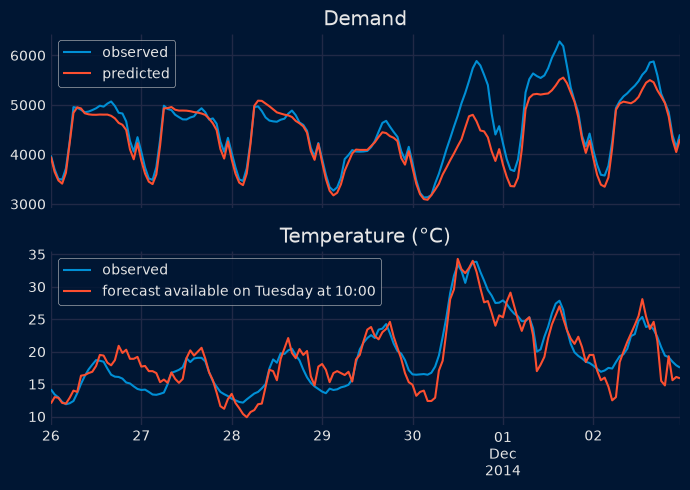

In [15]:
# Plot predictions and temperature forecasts used
# ==============================================================================
set_dark_theme()
fig, axs = plt.subplots(2, 1, figsize=(7, 5), sharex=True)
data.loc[predictions.index, "Demand"].plot(ax=axs[0], label="observed")
predictions.plot(ax=axs[0], label="predicted")
axs[0].set_title("Demand")
axs[0].legend()
data.loc[predictions.index, "Temperature"].plot(ax=axs[1], label="observed")
exog_future.loc[predictions.index, "temperature"].plot(
    ax=axs[1], label="forecast available on Tuesday at 10:00"
)
axs[1].set_title("Temperature (°C)")
axs[1].set_xlabel("")
axs[1].legend()
fig.tight_layout()
plt.show()

## Conclusions

- A backtest that predicts with the observed values of a forecasted exogenous variable is optimistic. In this example, the error estimated with the forecasts available at prediction time is 8.1% higher than the one estimated with the observed temperature.
- To evaluate the model as it will work in production, configure `TimeSeriesFold` (`steps`, `gap` and `fold_stride`) so that each fold reproduces the forecasting process, and build the exogenous variable with the last value published up to the moment of each prediction, obtained from the parameters of `TimeSeriesFold`.
- Training with the observed values only needs archived forecasts for the backtesting period, and requires `refit=False` in the backtest. Training with the forecasts needs archived forecasts for the whole history and works with any value of `refit`. Compare both options.
- A single exogenous column holds one value per timestamp. If the same timestamp is evaluated from several moments (overlapping folds, `fold_stride < steps`), split the process into several backtests without overlap, each with its own exogenous column: for example, predicting the next 7 days every day can be evaluated with 7 weekly backtests whose `initial_train_size` differs by 24 hours.
- If the model is retrained in each fold with the observed values (`refit=True`), the exogenous variable has to be built for each fold: get the folds with the `split` method of `TimeSeriesFold` and call `fit` and `predict` for each one.
- The same approach applies to any exogenous variable that is a forecast: weather, prices, plans or the predictions of another model.

For more details, see the [Exogenous variables](../user_guides/exogenous-variables.html) and [Backtesting](../user_guides/backtesting.html) user guides.